In [15]:
# Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    classification_report)

import shap

(5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
col:  id


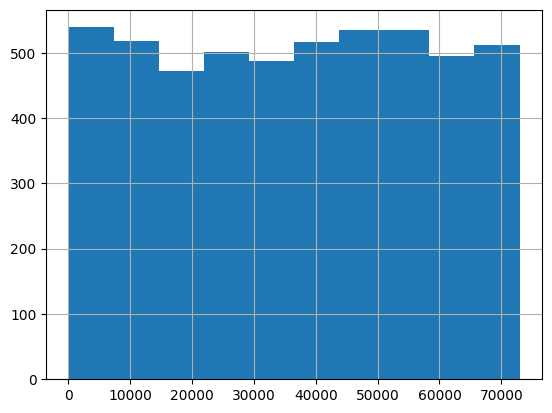

col:  gender


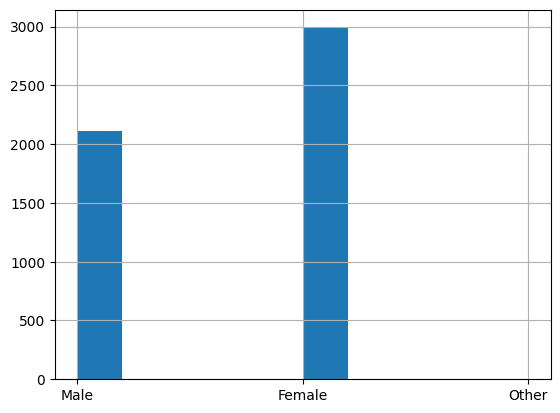

col:  age


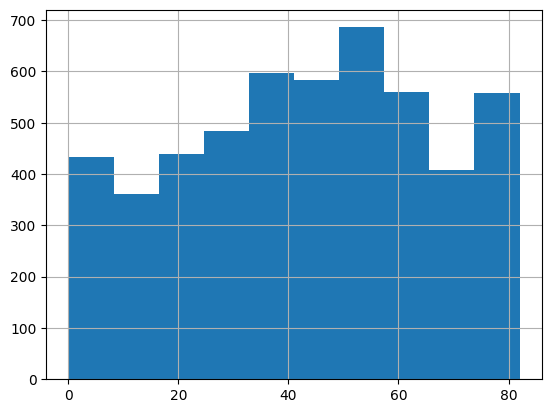

col:  hypertension


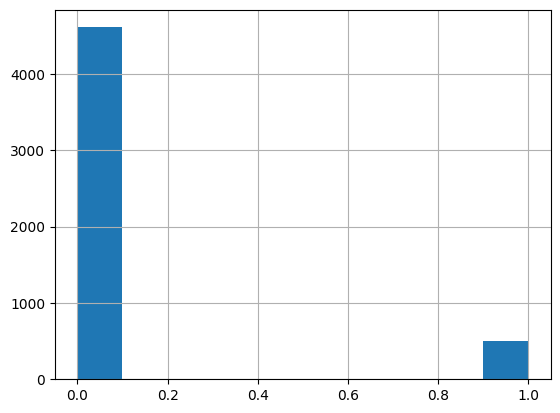

col:  heart_disease


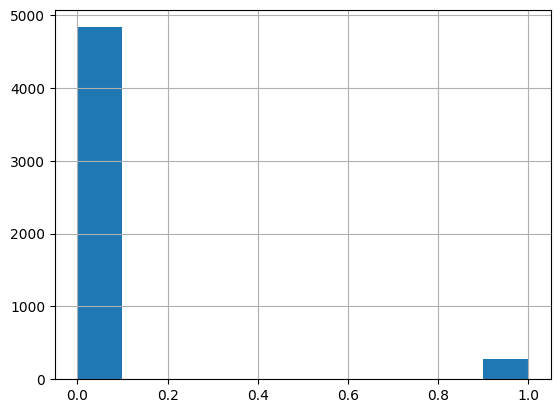

col:  ever_married


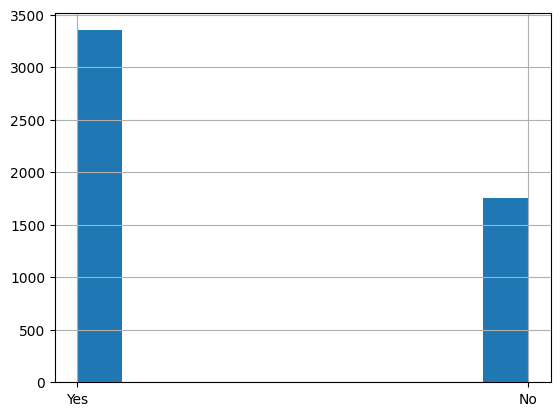

col:  work_type


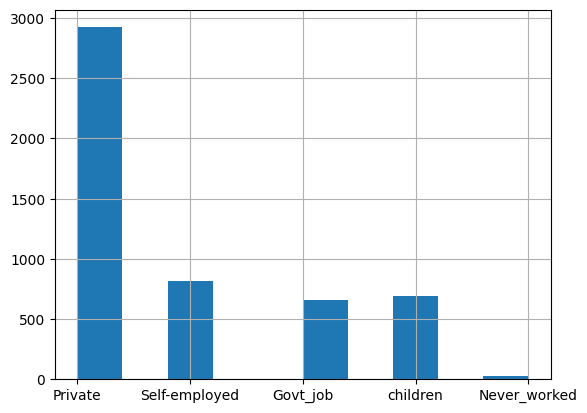

col:  Residence_type


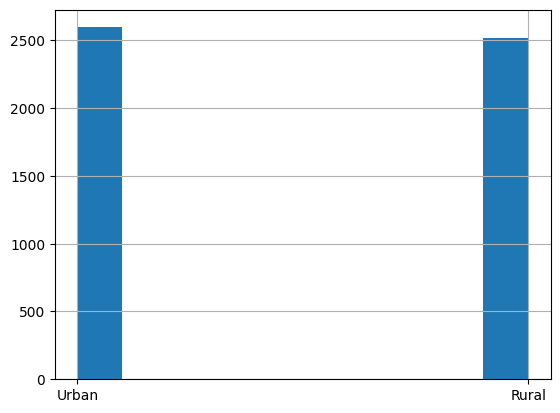

col:  avg_glucose_level


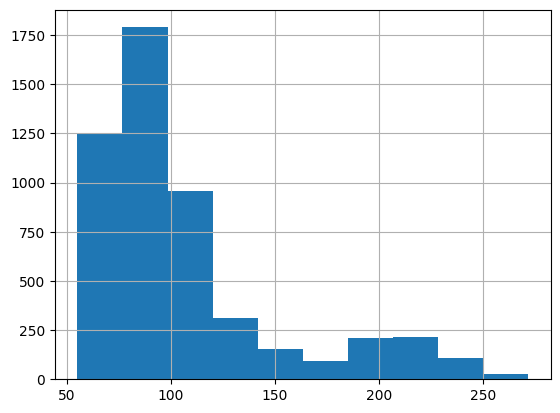

col:  bmi


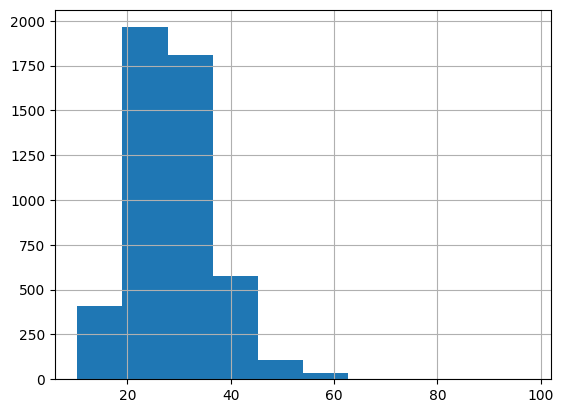

col:  smoking_status


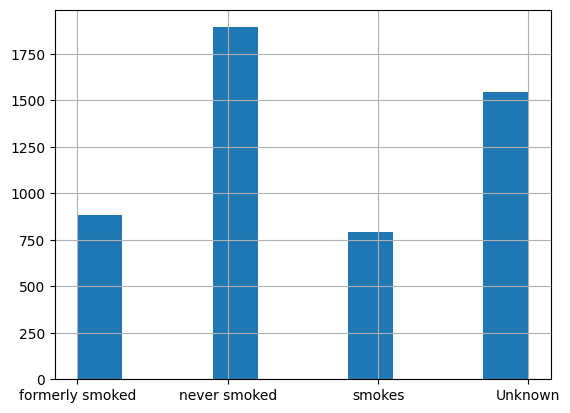

col:  stroke


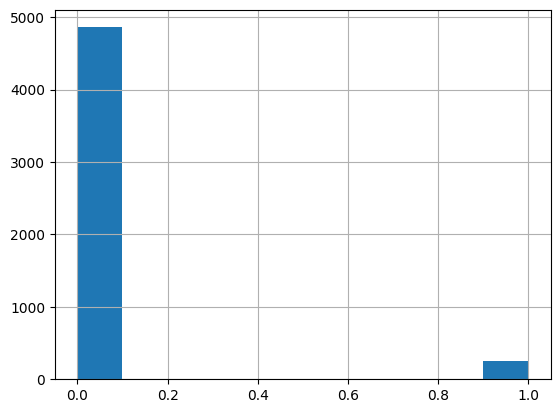

,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
0,False,True,False,False,True,False,False,True,False,False,False,True,False,True,False,False,67.0,0,1,228.69,36.6,1
1,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,61.0,0,0,202.21,0.0,1
2,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,80.0,0,1,105.92,32.5,1
3,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True,49.0,0,0,171.23,34.4,1
4,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,79.0,1,0,174.12,24.0,1


In [17]:
# 00_data_exploration.py

# %% Load data
data_loader = DataLoader()
data_loader.load_dataset("healthcare-dataset-stroke-data.csv")
data = data_loader.data

# %% Show head
print(data.shape)
data.head()

# %% Show general statistics
data.info()

# %% Show histogram for all columns
columns = data.columns
for col in columns:
    print("col: ", col)
    data[col].hist()
    plt.show()

# %% Show preprocessed dataframe
data_loader.preprocess_data()
data_loader.data.head()

Rows, columns: (5110, 12)
Duplicate rows: 0 | duplicate ids: 0

Missing values:
        n     %
bmi  201  3.93

Stroke counts: n0 = 4861, n1 = 249, % positive = 4.87

Numeric summary (overall):
            age  avg_glucose_level      bmi
count   5110.00            5110.00  4909.00
mean      43.23             106.15    28.89
std       22.61              45.28     7.85
median    45.00              91.88    28.10
min        0.08              55.12    10.30
max       82.00             271.74    97.60

Numeric summary by stroke:
          age        avg_glucose_level            bmi       
         mean median              mean  median   mean median
stroke                                                      
0       41.97   43.0            104.80   91.47  28.82   28.0
1       67.73   71.0            132.54  105.22  30.47   29.7

Categorical distributions:

gender
            n     %
gender            
Female  2994  58.6
Male    2115  41.4
Other      1   0.0

ever_married
                  n

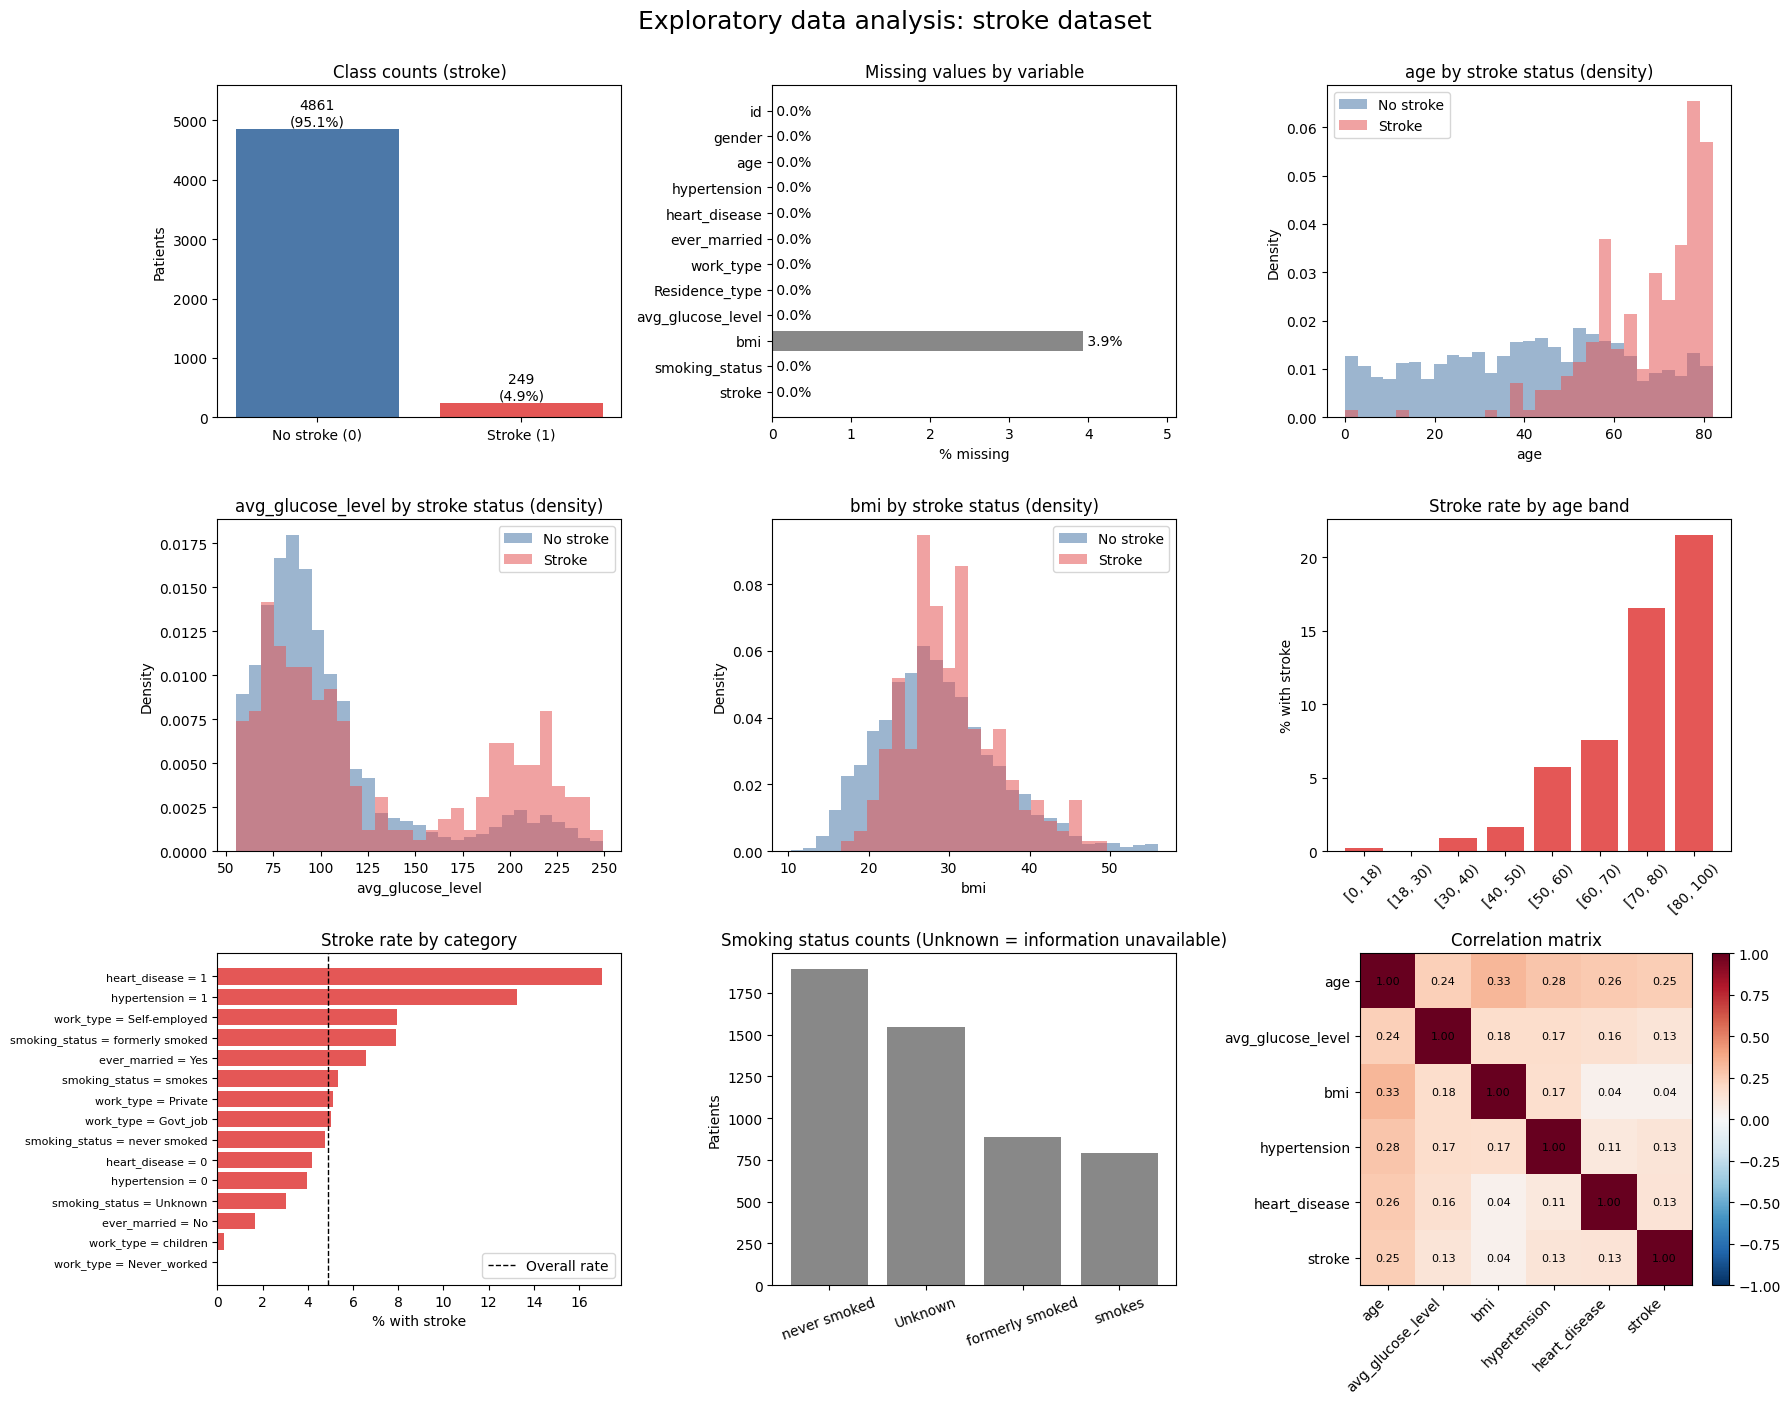

In [11]:
# EDA Panel

SV_PATH = "healthcare-dataset-stroke-data.csv"
df = pd.read_csv(SV_PATH)

num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
bin_cols = ["hypertension", "heart_disease"]
NEG, POS = "#4C78A8", "#E45756"

# 1. Summary tables
print("Rows, columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum(), "| duplicate ids:", df["id"].duplicated().sum())

miss = df.isna().sum()
print("\nMissing values:\n", pd.DataFrame({"n": miss, "%": (miss / len(df) * 100).round(2)})[miss > 0])

counts = df["stroke"].value_counts().sort_index()
print(f"\nStroke counts: n0 = {counts[0]}, n1 = {counts[1]}, % positive = {counts[1] / len(df) * 100:.2f}")

print("\nNumeric summary (overall):")
print(df[num_cols].agg(["count", "mean", "std", "median", "min", "max"]).round(2))
print("\nNumeric summary by stroke:")
print(df.groupby("stroke")[num_cols].agg(["mean", "median"]).round(2))

print("\nCategorical distributions:")
for c in cat_cols + bin_cols:
    t = df[c].value_counts()
    print(f"\n{c}\n", pd.DataFrame({"n": t, "%": (t / len(df) * 100).round(1)}))

# 2. The panel
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
ax = axes.ravel()

# (a) class counts
bars = ax[0].bar(["No stroke (0)", "Stroke (1)"], counts.values, color=[NEG, POS])
for b, v in zip(bars, counts.values):
    ax[0].text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / len(df):.1%})", ha="center", va="bottom")
ax[0].set_title("Class counts (stroke)"); ax[0].set_ylabel("Patients"); ax[0].set_ylim(0, counts.max() * 1.15)

# (b) missingness
m = df.isna().mean().mul(100)
ax[1].barh(m.index, m.values, color="#888888")
ax[1].invert_yaxis(); ax[1].set_xlabel("% missing"); ax[1].set_title("Missing values by variable")
for i, v in enumerate(m.values):
    ax[1].text(v, i, f" {v:.1f}%", va="center")
ax[1].set_xlim(0, max(m.max() * 1.3, 1))

# (c-e) numeric distributions by stroke (density-normalised so the small class is visible)
for k, col in enumerate(num_cols):
    a = ax[2 + k]
    lo, hi = df[col].quantile([0.0, 0.995])
    bins = np.linspace(lo, hi, 30)
    for s, colr, lab in [(0, NEG, "No stroke"), (1, POS, "Stroke")]:
        a.hist(df.loc[df.stroke == s, col].dropna(), bins=bins, density=True, alpha=0.55, color=colr, label=lab)
    a.set_title(f"{col} by stroke status (density)"); a.set_xlabel(col); a.set_ylabel("Density"); a.legend()

# (f) stroke rate by age band
bands = pd.cut(df["age"], [0, 18, 30, 40, 50, 60, 70, 80, 100], right=False)
rate = df.groupby(bands, observed=True)["stroke"].mean().mul(100)
ax[5].bar(rate.index.astype(str), rate.values, color=POS)
ax[5].set_title("Stroke rate by age band"); ax[5].set_ylabel("% with stroke"); ax[5].tick_params(axis="x", rotation=45)

# (g) stroke rate by categorical / binary variable
rows = []
for c in bin_cols + ["ever_married", "smoking_status", "work_type"]:
    for lvl, r in df.groupby(c)["stroke"].mean().mul(100).items():
        rows.append((f"{c} = {lvl}", r))
r = pd.DataFrame(rows, columns=["group", "rate"]).sort_values("rate")
ax[6].barh(r["group"], r["rate"], color=POS)
ax[6].axvline(df["stroke"].mean() * 100, color="k", ls="--", lw=1, label="Overall rate")
ax[6].set_title("Stroke rate by category"); ax[6].set_xlabel("% with stroke"); ax[6].legend()
ax[6].tick_params(axis="y", labelsize=8)

# (h) category counts for smoking_status (shows 'Unknown' share)
sm = df["smoking_status"].value_counts()
ax[7].bar(sm.index, sm.values, color="#888888")
ax[7].set_title("Smoking status counts (Unknown = information unavailable)")
ax[7].tick_params(axis="x", rotation=20); ax[7].set_ylabel("Patients")

# (i) correlation of numeric/binary variables with stroke
corr = df[num_cols + bin_cols + ["stroke"]].corr()
im = ax[8].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[8].set_xticks(range(len(corr))); ax[8].set_xticklabels(corr.columns, rotation=45, ha="right")
ax[8].set_yticks(range(len(corr))); ax[8].set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax[8].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[8].set_title("Correlation matrix"); fig.colorbar(im, ax=ax[8], fraction=0.046)

fig.suptitle("Exploratory data analysis: stroke dataset", fontsize=18, y=1.0)
plt.tight_layout()
plt.savefig("eda_panel.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
#Loading / Preprocessing

data_loader = DataLoader()
data_loader.load_dataset("healthcare-dataset-stroke-data.csv")
data_loader.preprocess_data()

#Split fr evaluation
X_train, X_test, y_train, y_test = data_loader.get_data_split()

#Oversampling
X_train, y_train, = data_loader.oversample(X_train, y_train)
print(X_train.shape)
print(X_test.shape)

(7778, 21)
(1022, 21)


In [4]:
# Fit Black Box Model

rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print(f"F1 Score: {f1_score(y_test, y_pred, average='macro')}")
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")


F1 Score: 0.5312473277101877
Accuracy: 0.9422700587084148


In [5]:
# SHAP Explainer

explainer = shap.TreeExplainer(rf)

# Calculation of Shapley Values for Test Data

# Select the patients to explain
start_index = 1
end_index = 100

X_explain = X_test.iloc[start_index:end_index]

# Calculate SHAP values for these patients
shap_values = explainer.shap_values(X_explain)

print("Number of patients:", len(X_explain))
print("SHAP dimensions:", shap_values.shape)

Number of patients: 99
SHAP dimensions: (99, 21, 2)


In [6]:
#Investigating Values(Classification problem)

# class 0 = contribution to class 1
# class 1 = contribution to class 2

print(shap_values[0].shape)
shap_values

(21, 2)


array([[[ 8.44304699e-03, -8.44304699e-03],
        [ 8.56952645e-03, -8.56952645e-03],
        [-6.33798015e-07,  6.33798015e-07],
        ...,
        [ 1.00055778e-02, -1.00055778e-02],
        [ 9.85194909e-02, -9.85194909e-02],
        [ 7.61917004e-02, -7.61917004e-02]],

       [[ 6.53625793e-03, -6.53625793e-03],
        [ 6.46550876e-03, -6.46550876e-03],
        [-7.24225548e-07,  7.24225548e-07],
        ...,
        [ 8.40246963e-03, -8.40246963e-03],
        [ 5.94191689e-02, -5.94191689e-02],
        [ 4.18239246e-02, -4.18239246e-02]],

       [[ 5.67394472e-04, -5.67394472e-04],
        [ 1.69219138e-03, -1.69219138e-03],
        [-1.05065164e-06,  1.05065164e-06],
        ...,
        [ 9.22320553e-03, -9.22320553e-03],
        [ 7.27109455e-02, -7.27109455e-02],
        [ 5.45376625e-02, -5.45376625e-02]],

       ...,

       [[ 7.39024030e-03, -7.39024030e-03],
        [ 7.29662543e-03, -7.29662543e-03],
        [-1.00603268e-06,  1.00603268e-06],
        ...,
     

In [7]:
#Visualization of local predictions
shap.initjs()

# Select a patient within the SHAP sample
offset = 1

# Retrieve exactly the same patient used for SHAP
selected_patient = X_explain.iloc[[offset]]

# Predict using that exact patient
prediction = rf.predict(selected_patient)[0]

print("Original test position:", start_index + offset)
print("Patient ID:", selected_patient.index[0])
print("Actual class:", y_test.loc[selected_patient.index[0]])
print("Predicted class:", prediction)

# Generate force plot for the same patient
shap.force_plot(
    explainer.expected_value[1],
    shap_values[offset, :, 1],
    selected_patient.iloc[0]
)


Original test position: 2
Patient ID: 451
Actual class: 0
Predicted class: 0


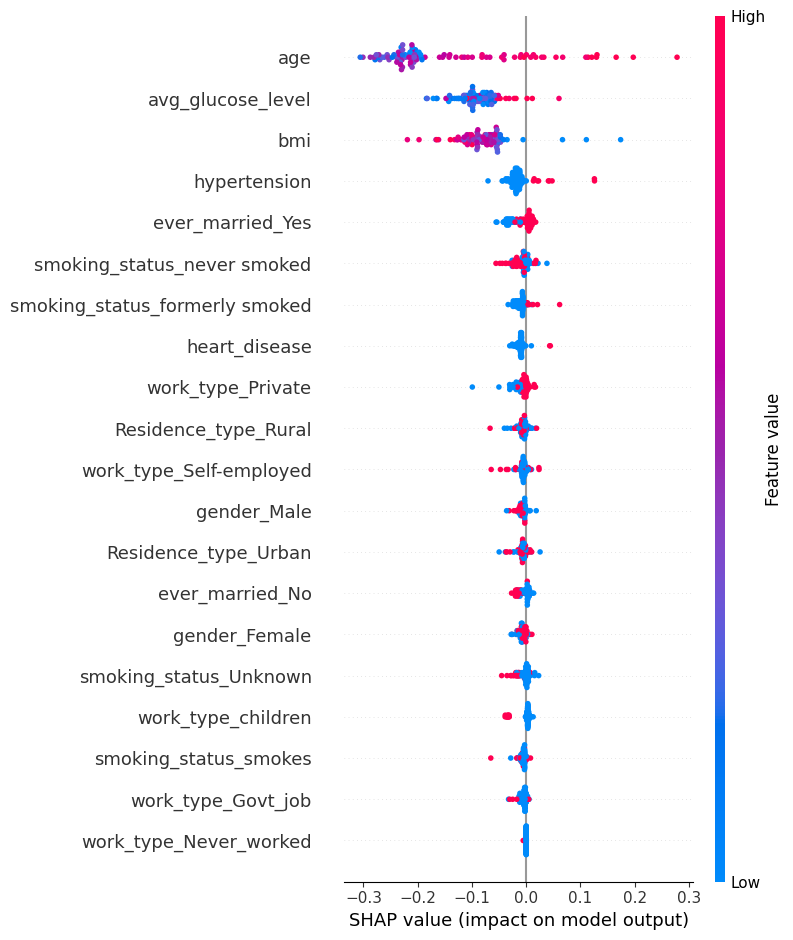

In [8]:
#Visualization of global features

shap.summary_plot(shap_values[:, :, 1], X_test[start_index:end_index])

In [9]:
# 1. Test-set metrics (3.1)
y_pred  = rf.predict(X_test)                 # default ~0.5 majority vote
y_score = rf.predict_proba(X_test)[:, 1]     # probability of stroke = 1

# Check that column 1 really is stroke = 1
print("rf.classes_:", rf.classes_)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

print(f"Accuracy:               {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy:      {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (stroke = 1): {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall (stroke = 1):    {recall_score(y_test, y_pred):.4f}")
print(f"F1 (stroke = 1):        {f1_score(y_test, y_pred):.4f}")
print(f"Macro F1:               {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC AUC:                {roc_auc_score(y_test, y_score):.4f}")
print(f"Average precision:      {average_precision_score(y_test, y_score):.4f}")
print(f"Prevalence (test):      {y_test.mean():.4f}  (positives = {int(y_test.sum())} of {len(y_test)})")
print(f"Confusion matrix  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print()
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

# 2. Model probability for the selected patient (4.1)
selected_patient = X_explain.iloc[[offset]]
proba = rf.predict_proba(selected_patient)[0, 1]

base_value = explainer.expected_value[1]
shap_sum   = shap_values[offset, :, 1].sum()
print(f"\nPatient row index: {selected_patient.index[0]}")
print(f"predict_proba (stroke = 1): {proba:.6f}")
print(f"Base value:                 {base_value:.6f}")
print(f"Sum of SHAP values:         {shap_sum:.6f}")
print(f"Base + sum:                 {base_value + shap_sum:.6f}")
print(f"Reconstruction residual:    {abs(proba - (base_value + shap_sum)):.2e}")

# Probabilities for several patients at once (e.g. the first 5 explained)
several = X_explain.iloc[:5]
print(pd.Series(rf.predict_proba(several)[:, 1], index=several.index,
                name="P(stroke=1)").round(4))

# 3. Mean absolute SHAP values (5.2)
sv = shap_values[:, :, 1]                    # stroke = 1 output
mean_abs = (pd.Series(np.abs(sv).mean(axis=0), index=X_explain.columns)
              .sort_values(ascending=False))
print("\nMean |SHAP| (top 10):")
print(mean_abs.head(10).round(4))

# Positive-class count in the explained sample (5.1)
print("\nStroke = 1 cases in explained sample:", int(y_test.loc[X_explain.index].sum()),
      "of", len(X_explain))

rf.classes_: [0 1]
Accuracy:               0.9423
Balanced accuracy:      0.5238
Precision (stroke = 1): 0.2000
Recall (stroke = 1):    0.0600
F1 (stroke = 1):        0.0923
Macro F1:               0.5312
ROC AUC:                0.7383
Average precision:      0.1300
Prevalence (test):      0.0489  (positives = 50 of 1022)
Confusion matrix  TN=960  FP=12  FN=47  TP=3

              precision    recall  f1-score   support

           0     0.9533    0.9877    0.9702       972
           1     0.2000    0.0600    0.0923        50

    accuracy                         0.9423      1022
   macro avg     0.5767    0.5238    0.5312      1022
weighted avg     0.9165    0.9423    0.9272      1022


Patient row index: 451
predict_proba (stroke = 1): 0.000000
Base value:                 0.500899
Sum of SHAP values:         -0.500899
Base + sum:                 0.000000
Reconstruction residual:    9.99e-16
2813    0.0
451     0.0
3133    0.0
5005    0.0
3096    0.0
Name: P(stroke=1), dtype: float64